<a href="https://colab.research.google.com/github/yozophy/solar-wind-magnetosphere-xgboost-forecast/blob/main/Prediksi_Badai_Geomagnetik.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Import Library & Baca Data Mentah

In [ ]:
!pip install optuna
import optuna
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from xgboost import XGBClassifier
import numpy as np
from google.colab import drive
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, recall_score, f1_score, precision_score
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns


# 1. Mount Google Drive untuk mengakses file .lst
drive.mount('/content/drive')

# 2. Definisikan nama kolom (SANGAT PENTING: Sesuaikan dengan urutan list saat kamu download di OMNIWeb)
columns = [
    'Year', 'Day', 'Hour',
    'IMF_Mag_Avg', 'Bz_GSM', 'By_GSM',
    'Proton_Density', 'Flow_Speed', 'Flow_Pressure', 'Ey', 'Dst'
]

# 3. Tentukan path file (Ganti bagian ini sesuai lokasi file .lst kamu di Drive)
file_path = '/content/drive/MyDrive/Skripsi/PROGRAM/omni_data.lst'

# 4. Membaca file OMNIWeb
# - delim_whitespace=True: karena data dipisahkan oleh spasi yang tidak beraturan
# - na_values: langsung mengubah angka 'fill values' instrumen satelit menjadi NaN (Not a Number)
df = pd.read_csv(file_path,
                 delim_whitespace=True,
                 names=columns,
                 na_values=['99.9', '99.99', '999.9', '9999.99', '99999.9'])

# 5. Inspeksi awal (Melihat struktur data dan 5 baris pertama)
print("--- Informasi Struktur Data ---")
df.info()

print("\n--- 5 Baris Pertama Dataset ---")
display(df.head())





   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.4/270.4 kB 22.9 MB/s eta 0:00:00
Mounted at /content/drive


/tmp/ipykernel_7761/2337884899.py:30: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path,


--- Informasi Struktur Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Year            35064 non-null  int64  
 1   Day             35064 non-null  int64  
 2   Hour            35064 non-null  int64  
 3   IMF_Mag_Avg     35064 non-null  float64
 4   Bz_GSM          35064 non-null  float64
 5   By_GSM          35064 non-null  float64
 6   Proton_Density  34681 non-null  float64
 7   Flow_Speed      35064 non-null  float64
 8   Flow_Pressure   34677 non-null  float64
 9   Ey              35064 non-null  float64
 10  Dst             35064 non-null  int64  
dtypes: float64(7), int64(4)
memory usage: 2.9 MB

--- 5 Baris Pertama Dataset ---


,Year,Day,Hour,IMF_Mag_Avg,Bz_GSM,By_GSM,Proton_Density,Flow_Speed,Flow_Pressure,Ey,Dst
0,2012,1,0,4.0,0.1,0.8,7.2,379.0,1.95,-0.30,-8
1,2012,1,1,4.4,3.4,-1.9,7.8,386.0,2.19,0.73,-3
2,2012,1,2,4.8,3.8,0.1,7.0,380.0,1.91,-0.04,-4
3,2012,1,3,5.4,1.5,-2.4,7.6,374.0,2.04,0.90,-5
4,2012,1,4,4.5,1.4,-1.8,7.2,369.0,1.89,0.66,-9


#Pembuatan Time-Series Index

In [ ]:
# 1. Menggabungkan Year dan Day (Day of Year) menjadi string, lalu parsing sebagai Datetime
# str.zfill(3) memastikan format hari selalu 3 digit (misal: hari ke-4 menjadi '004')
tanggal = pd.to_datetime(df['Year'].astype(str) + df['Day'].astype(str).str.zfill(3), format='%Y%j')

# 2. Menambahkan Jam (Hour) ke dalam Datetime
df['Datetime'] = tanggal + pd.to_timedelta(df['Hour'], unit='h')

# 3. Menjadikan Datetime sebagai index DataFrame dan menghapus kolom waktu lama
df = df.set_index('Datetime')
df = df.drop(columns=['Year', 'Day', 'Hour'])

# 4. Inspeksi hasil Datetime index
print("--- 5 Baris Pertama dengan Datetime Index ---")
display(df.head())

print("\n--- Cek Missing Values Saat Ini ---")
print(df.isna().sum())

--- 5 Baris Pertama dengan Datetime Index ---


,IMF_Mag_Avg,Bz_GSM,By_GSM,Proton_Density,Flow_Speed,Flow_Pressure,Ey,Dst
Datetime,,,,,,,,
2012-01-01 00:00:00,4.0,0.1,0.8,7.2,379.0,1.95,-0.30,-8
2012-01-01 01:00:00,4.4,3.4,-1.9,7.8,386.0,2.19,0.73,-3
2012-01-01 02:00:00,4.8,3.8,0.1,7.0,380.0,1.91,-0.04,-4
2012-01-01 03:00:00,5.4,1.5,-2.4,7.6,374.0,2.04,0.90,-5
2012-01-01 04:00:00,4.5,1.4,-1.8,7.2,369.0,1.89,0.66,-9



--- Cek Missing Values Saat Ini ---
IMF_Mag_Avg         0
Bz_GSM              0
By_GSM              0
Proton_Density    383
Flow_Speed          0
Flow_Pressure     387
Ey                  0
Dst                 0
dtype: int64


#Penanganan Missing Values (Data Satelit)

In [ ]:
print(f"Jumlah baris sebelum pembersihan: {len(df)}")

# 1. Interpolasi berbasis waktu (maksimal menambal kekosongan 3 jam berturut-turut)
# Metode 'time' sangat akurat karena memperhitungkan jarak waktu sesungguhnya pada index
df_cleaned = df.interpolate(method='time', limit=3)

# 2. Cek berapa banyak NaN yang masih tersisa setelah interpolasi
print("\n--- Sisa NaN setelah interpolasi (Celah > 3 jam) ---")
print(df_cleaned.isna().sum())

# 3. Buang baris yang masih memiliki NaN (celah data terlalu besar, tidak boleh direkayasa)
df_cleaned = df_cleaned.dropna()

print(f"\nJumlah baris setelah membuang celah besar: {len(df_cleaned)}")
print(f"Total data yang terbuang: {len(df) - len(df_cleaned)} baris")

# 4. Pastikan tidak ada data kosong lagi
print("\n--- Cek Final Missing Values ---")
print(df_cleaned.isna().sum())

Jumlah baris sebelum pembersihan: 35064

--- Sisa NaN setelah interpolasi (Celah > 3 jam) ---
IMF_Mag_Avg         0
Bz_GSM              0
By_GSM              0
Proton_Density    276
Flow_Speed          0
Flow_Pressure     276
Ey                  0
Dst                 0
dtype: int64

Jumlah baris setelah membuang celah besar: 34788
Total data yang terbuang: 276 baris

--- Cek Final Missing Values ---
IMF_Mag_Avg       0
Bz_GSM            0
By_GSM            0
Proton_Density    0
Flow_Speed        0
Flow_Pressure     0
Ey                0
Dst               0
dtype: int64


#Pembuatan Target Klasifikasi (Y) dan Fitur (X)

In [ ]:
# 1. Binarisasi Target berdasarkan ambang batas fisika (Dst <= -50 nT)
df_cleaned['Storm_Class'] = (df_cleaned['Dst'] <= -50).astype(int)

# 2. Definisikan Fitur (X) dan Target (y)
# Dst dibuang dari X untuk mencegah data leakage
fitur = ['IMF_Mag_Avg', 'Bz_GSM', 'By_GSM', 'Proton_Density', 'Flow_Speed', 'Flow_Pressure', 'Ey']
X = df_cleaned[fitur]
y = df_cleaned['Storm_Class']

# 3. Cek Distribusi Kelas (Imbalance Check)
print("--- Jumlah Kejadian (Jam) ---")
print(y.value_counts())

print("\n--- Persentase Kejadian (%) ---")
print((y.value_counts(normalize=True) * 100).round(2))

--- Jumlah Kejadian (Jam) ---
Storm_Class
0    33182
1     1606
Name: count, dtype: int64

--- Persentase Kejadian (%) ---
Storm_Class
0    95.38
1     4.62
Name: proportion, dtype: float64


#Train-Test Split & Hyperparameter Tuning (Optuna)

In [ ]:
# 1. Membagi data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Jumlah data latih (Train): {len(X_train)} jam")
print(f"Jumlah data uji (Test): {len(X_test)} jam")

# 2. Menghitung rasio kelas untuk scale_pos_weight
rasio_kelas = len(y_train[y_train == 0]) / len(y_train[y_train == 1])
print(f"Nilai scale_pos_weight: {rasio_kelas:.2f}\n")

# 3. Mendefinisikan Fungsi Objektif untuk Optuna
def objective(trial):
    # Ruang pencarian parameter
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'scale_pos_weight': rasio_kelas, # Tetap kita kunci di sini untuk imbalanced data
        'eval_metric': 'aucpr',
        'random_state': 42,
        'tree_method': 'hist' # Mempercepat komputasi di Colab
    }

    # Inisialisasi model dengan parameter dari trial
    model = XGBClassifier(**param)

    # Validasi Silang (Cross-Validation) untuk mencegah overfitting
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

    # Metrik yang dioptimasi adalah 'average_precision' (Area Under Precision-Recall Curve)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='average_precision', n_jobs=-1)

    return scores.mean()

# 4. Menjalankan Proses Optimasi Optuna
print("Memulai pencarian hyperparameter terbaik dengan Optuna...")
# TPE (Tree-structured Parzen Estimator) adalah algoritma bawaan Optuna
study = optuna.create_study(direction='maximize')

# n_trials=20 cukup untuk tahap awal.
study.optimize(objective, n_trials=100)

# 5. Mengambil Parameter Terbaik
print("\n[SUKSES] Optimasi Selesai!")
print(f"Skor PR-AUC Terbaik (Cross-Validation): {study.best_value:.4f}")
print("Parameter Terbaik:")
best_params = study.best_params
for key, value in best_params.items():
    print(f"  {key}: {value}")

# 6. Membangun model final dengan parameter terbaik
best_params['scale_pos_weight'] = rasio_kelas
best_params['eval_metric'] = 'aucpr'
best_params['random_state'] = 42

final_xgb_model = XGBClassifier(**best_params)
print("\nArsitektur XGBoost Final siap dilatih di Cell selanjutnya!")

[I 2026-10-21 02:33:34,266] A new study created in memory with name: no-name-d7bc15eb-4008-4a04-9d64-efd804420019


Jumlah data latih (Train): 27830 jam
Jumlah data uji (Test): 6958 jam
Nilai scale_pos_weight: 20.66

Memulai pencarian hyperparameter terbaik dengan Optuna...


[I 2026-10-21 02:34:04,503] Trial 0 finished with value: 0.5174777788664274 and parameters: {'n_estimators': 350, 'max_depth': 7, 'learning_rate': 0.03377638520297586, 'subsample': 0.9792550598621286, 'colsample_bytree': 0.8402060392193889}. Best is trial 0 with value: 0.5174777788664274.
[I 2026-10-21 02:34:09,194] Trial 1 finished with value: 0.5035511584135709 and parameters: {'n_estimators': 150, 'max_depth': 6, 'learning_rate': 0.26719932475772423, 'subsample': 0.9559933785241126, 'colsample_bytree': 0.9653613350999685}. Best is trial 0 with value: 0.5174777788664274.
[I 2026-10-21 02:34:11,253] Trial 2 finished with value: 0.4858019190851522 and parameters: {'n_estimators': 150, 'max_depth': 4, 'learning_rate': 0.17053022252586797, 'subsample': 0.6635553126789652, 'colsample_bytree': 0.7296220461569586}. Best is trial 0 with value: 0.5174777788664274.
[I 2026-10-21 02:34:18,735] Trial 3 finished with value: 0.5237477683533043 and parameters: {'n_estimators': 250, 'max_depth': 8, 


[SUKSES] Optimasi Selesai!
Skor PR-AUC Terbaik (Cross-Validation): 0.5390
Parameter Terbaik:
  n_estimators: 350
  max_depth: 9
  learning_rate: 0.041725683823753135
  subsample: 0.7542230513074448
  colsample_bytree: 0.9589847984555971

Arsitektur XGBoost Final siap dilatih di Cell selanjutnya!


#Pelatihan Model Final & Evaluasi (Test Set)

In [ ]:
# 1. Melatih (Fitting) Model Final
print("Melatih arsitektur XGBoost dengan data Train...")
final_xgb_model.fit(X_train, y_train)
print("[SUKSES] Model selesai dilatih!\n")

# 2. Melakukan Prediksi pada Data Uji (Test Set)
print("Menguji model pada Data Test (Unseen Data)...")
y_pred = final_xgb_model.predict(X_test)
y_prob = final_xgb_model.predict_proba(X_test)[:, 1] # Probabilitas untuk kelas 1 (Badai)

# 3. Laporan Klasifikasi (Precision, Recall, F1-Score)
print("\n--- Laporan Klasifikasi (Classification Report) ---")
print(classification_report(y_test, y_pred, target_names=['Tenang (Dst > -50)', 'Badai (Dst <= -50)']))

# 4. Skor PR-AUC pada Data Uji
pr_auc_test = average_precision_score(y_test, y_prob)
print(f"Skor Final PR-AUC pada Data Test: {pr_auc_test:.4f}")

# 5. Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Tenang', 'Prediksi Badai'],
            yticklabels=['Aktual Tenang', 'Aktual Badai'])
plt.title('Confusion Matrix - Prediksi Badai Geomagnetik\n(Puncak Siklus Matahari 24)')
plt.xlabel('Tebakan Model (XGBoost)')
plt.ylabel('Kenyataan Observasi (OMNIWeb)')
plt.show()

Melatih arsitektur XGBoost dengan data Train...


NameError: name 'final_xgb_model' is not defined

#Analisis Feature Importance (Fisika Interpretasi)

--- Kontribusi Parameter Angin Surya (Feature Importance) ---
     Parameter  Importance
   IMF_Mag_Avg    0.251032
            Ey    0.203629
    Flow_Speed    0.189433
 Flow_Pressure    0.093505
        By_GSM    0.088694
        Bz_GSM    0.087580
Proton_Density    0.086127


/tmp/ipykernel_1664/555608581.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Parameter', data=df_importance, palette='viridis')


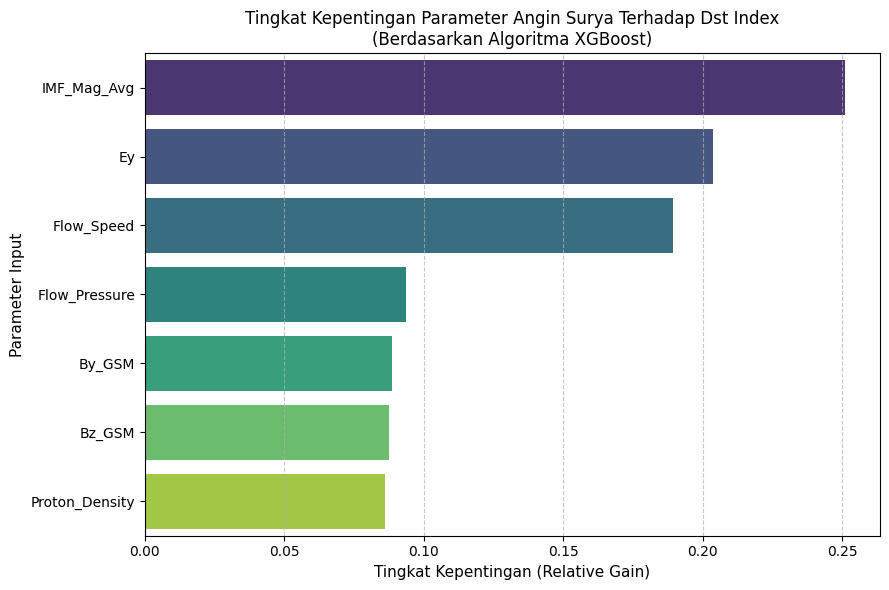

In [ ]:
# 1. Mengambil nilai importance (berdasarkan metrik 'gain' / kontribusi fitur terhadap model)
importances = final_xgb_model.feature_importances_
fitur = X_train.columns

# 2. Membuat DataFrame untuk memudahkan plotting
df_importance = pd.DataFrame({
    'Parameter': fitur,
    'Importance': importances
})

# 3. Mengurutkan dari yang paling penting ke yang paling tidak penting
df_importance = df_importance.sort_values(by='Importance', ascending=False)

# 4. Menampilkan tabel angka
print("--- Kontribusi Parameter Angin Surya (Feature Importance) ---")
print(df_importance.to_string(index=False))

# 5. Visualisasi Bar Chart
plt.figure(figsize=(9, 6))
sns.barplot(x='Importance', y='Parameter', data=df_importance, palette='viridis')
plt.title('Tingkat Kepentingan Parameter Angin Surya Terhadap Dst Index\n(Berdasarkan Algoritma XGBoost)', fontsize=12)
plt.xlabel('Tingkat Kepentingan (Relative Gain)', fontsize=11)
plt.ylabel('Parameter Input', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#Pembuatan Fitur Time-Lag (Sistem Peringatan Dini / Forecasting T+1)

Menyiapkan dataset untuk Forecasting T+1...
Melatih algoritma XGBoost untuk memprediksi masa depan...

--- Laporan Klasifikasi (FORECASTING T+1 JAM) ---
              precision    recall  f1-score   support

      Tenang       0.98      0.98      0.98      6637
       Badai       0.56      0.59      0.57       321

    accuracy                           0.96      6958
   macro avg       0.77      0.78      0.78      6958
weighted avg       0.96      0.96      0.96      6958

Skor Final PR-AUC (Forecasting): 0.6162


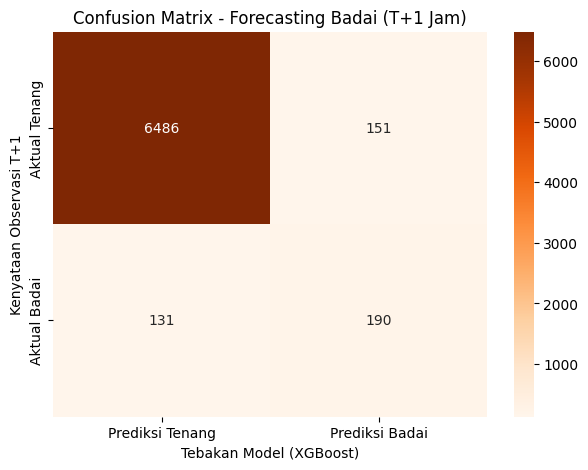

In [ ]:
print("Menyiapkan dataset untuk Forecasting T+1...")

# 1. Menggeser (Shift) Target 1 Jam ke Masa Depan
# Kita ingin fitur di jam T memprediksi badai di jam T+1
df_lag = df_cleaned.copy()
df_lag['Storm_Class_T+1'] = df_lag['Storm_Class'].shift(-1)

# Baris paling terakhir akan bernilai NaN karena tidak ada data T+1 setelahnya, jadi kita drop
df_lag = df_lag.dropna()

# 2. Mendefinisikan Fitur (X) di jam T dan Target (Y) di jam T+1
X_lag = df_lag[['IMF_Mag_Avg', 'Bz_GSM', 'By_GSM', 'Proton_Density', 'Flow_Speed', 'Flow_Pressure', 'Ey']]
y_lag = df_lag['Storm_Class_T+1'].astype(int)

# 3. Train-Test Split ulang
X_train_lag, X_test_lag, y_train_lag, y_test_lag = train_test_split(
    X_lag, y_lag, test_size=0.2, random_state=42, stratify=y_lag
)

# 4. Membangun model dengan parameter Optuna terbaik yang sudah kita dapatkan
# (Pastikan variabel rasio_kelas masih ada di memori Colab)
best_params_lag = {
    'n_estimators': 300,
    'max_depth': 9,
    'learning_rate': 0.06519017685642876,
    'subsample': 0.9263548298414471,
    'colsample_bytree': 0.923763630498289,
    'scale_pos_weight': rasio_kelas,
    'eval_metric': 'aucpr',
    'random_state': 42
}

model_forecasting = XGBClassifier(**best_params_lag)

# 5. Melatih Model Forecasting
print("Melatih algoritma XGBoost untuk memprediksi masa depan...")
model_forecasting.fit(X_train_lag, y_train_lag)

# 6. Evaluasi dan Prediksi
y_pred_lag = model_forecasting.predict(X_test_lag)
y_prob_lag = model_forecasting.predict_proba(X_test_lag)[:, 1]

# 7. Menampilkan Hasil
print("\n--- Laporan Klasifikasi (FORECASTING T+1 JAM) ---")
print(classification_report(y_test_lag, y_pred_lag, target_names=['Tenang', 'Badai']))

pr_auc_lag = average_precision_score(y_test_lag, y_prob_lag)
print(f"Skor Final PR-AUC (Forecasting): {pr_auc_lag:.4f}")

# 8. Visualisasi Matrix
cm_lag = confusion_matrix(y_test_lag, y_pred_lag)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_lag, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Prediksi Tenang', 'Prediksi Badai'],
            yticklabels=['Aktual Tenang', 'Aktual Badai'])
plt.title('Confusion Matrix - Forecasting Badai (T+1 Jam)')
plt.xlabel('Tebakan Model (XGBoost)')
plt.ylabel('Kenyataan Observasi T+1')
plt.show()

#Optimalisasi Ambang Batas (Threshold Tuning)
# Memaksimalkan F1-Score untuk Forecasting T+1

Mencari threshold probabilitas yang optimal...
-> F1-Score pada Threshold Default (0.50): 0.5740
-> F1-Score Tertinggi ditemukan pada Threshold: 0.49
-> Nilai F1-Score Optimal: 0.5744



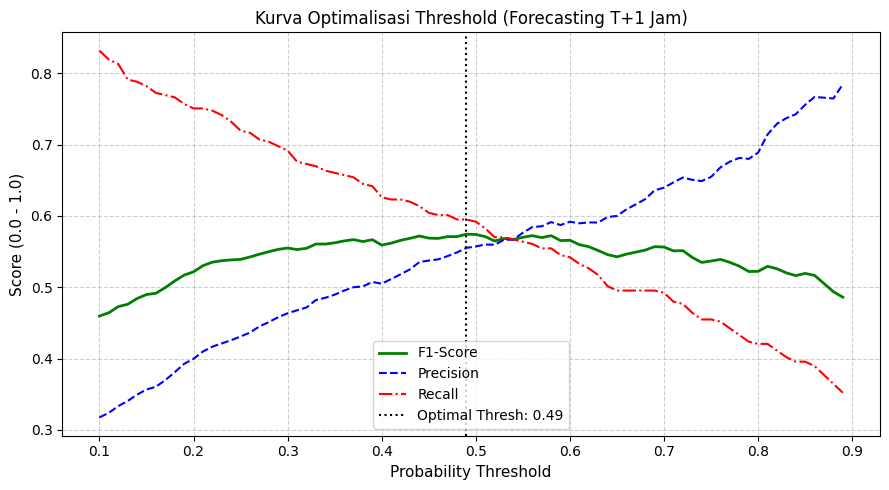

Menerapkan Threshold Optimal ke Data Test...

--- Laporan Klasifikasi (DENGAN THRESHOLD OPTIMAL) ---
              precision    recall  f1-score   support

      Tenang       0.98      0.98      0.98      6637
       Badai       0.56      0.60      0.57       321

    accuracy                           0.96      6958
   macro avg       0.77      0.79      0.78      6958
weighted avg       0.96      0.96      0.96      6958



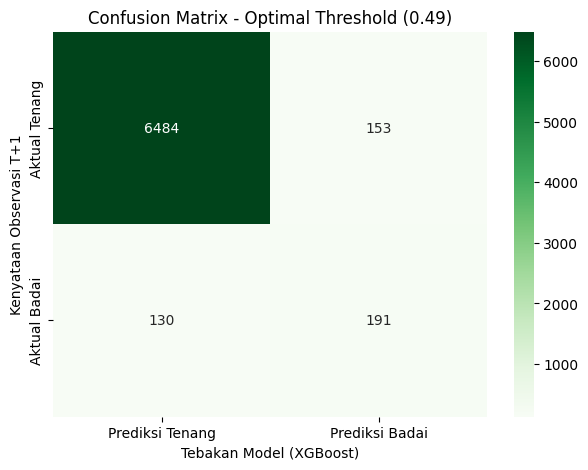

In [ ]:
print("Mencari threshold probabilitas yang optimal...")

# Kita uji probabilitas dari 0.10 hingga 0.90 dengan step 0.01
thresholds = np.arange(0.1, 0.9, 0.01)
f1_scores = []
precisions = []
recalls = []

for thresh in thresholds:
    # Prediksi biner manual berdasarkan threshold uji
    y_pred_thresh = (y_prob_lag >= thresh).astype(int)

    # Simpan metrik
    f1_scores.append(f1_score(y_test_lag, y_pred_thresh, zero_division=0))
    precisions.append(precision_score(y_test_lag, y_pred_thresh, zero_division=0))
    recalls.append(recall_score(y_test_lag, y_pred_thresh))

best_idx = np.argmax(f1_scores)
best_thresh = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"-> F1-Score pada Threshold Default (0.50): {f1_score(y_test_lag, (y_prob_lag >= 0.5).astype(int)):.4f}")
print(f"-> F1-Score Tertinggi ditemukan pada Threshold: {best_thresh:.2f}")
print(f"-> Nilai F1-Score Optimal: {best_f1:.4f}\n")

plt.figure(figsize=(9, 5))
plt.plot(thresholds, f1_scores, label='F1-Score', color='green', linewidth=2)
plt.plot(thresholds, precisions, label='Precision', color='blue', linestyle='--')
plt.plot(thresholds, recalls, label='Recall', color='red', linestyle='-.')
plt.axvline(best_thresh, color='black', linestyle=':', label=f'Optimal Thresh: {best_thresh:.2f}')

plt.title('Kurva Optimalisasi Threshold (Forecasting T+1 Jam)', fontsize=12)
plt.xlabel('Probability Threshold', fontsize=11)
plt.ylabel('Score (0.0 - 1.0)', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("Menerapkan Threshold Optimal ke Data Test...")
y_pred_best = (y_prob_lag >= best_thresh).astype(int)

print("\n--- Laporan Klasifikasi (DENGAN THRESHOLD OPTIMAL) ---")
print(classification_report(y_test_lag, y_pred_best, target_names=['Tenang', 'Badai']))

cm_opt = confusion_matrix(y_test_lag, y_pred_best)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Prediksi Tenang', 'Prediksi Badai'],
            yticklabels=['Aktual Tenang', 'Aktual Badai'])
plt.title(f'Confusion Matrix - Optimal Threshold ({best_thresh:.2f})')
plt.xlabel('Tebakan Model (XGBoost)')
plt.ylabel('Kenyataan Observasi T+1')
plt.show()

#Feature Engineering (Memori Historis) + Forecasting T+1

In [ ]:
print("1. Merekayasa Fitur Historis (Rolling Window 3 dan 6 Jam)...")
# Menggunakan df_cleaned agar kita memodifikasi dari data yang utuh dan berurut
df_fe = df_cleaned.copy()

# Fitur yang secara fisika paling berpengaruh menabung energi
fitur_utama = ['Bz_GSM', 'Ey', 'Flow_Speed', 'IMF_Mag_Avg']

for col in fitur_utama:
    df_fe[f'{col}_mean_3h'] = df_fe[col].rolling(window=3).mean()
    df_fe[f'{col}_mean_6h'] = df_fe[col].rolling(window=6).mean()

# Membuang 5 baris pertama di tahun 2012 yang bernilai NaN karena proses rolling
df_fe = df_fe.dropna()

print("2. Menggeser Target 1 Jam ke Masa Depan (Forecasting T+1)...")
df_fe['Storm_Class_T+1'] = df_fe['Storm_Class'].shift(-1)
# Baris paling ujung tahun 2015 akan NaN, kita buang
df_fe = df_fe.dropna()

print("3. Memisahkan Data Latih dan Data Uji (Train-Test Split)...")
# Daftar 15 fitur komprehensif kita sekarang (Kondisi saat ini + Masa lalu)
fitur_semua = [
    'IMF_Mag_Avg', 'Bz_GSM', 'By_GSM', 'Proton_Density', 'Flow_Speed', 'Flow_Pressure', 'Ey',
    'Bz_GSM_mean_3h', 'Bz_GSM_mean_6h',
    'Ey_mean_3h', 'Ey_mean_6h',
    'Flow_Speed_mean_3h', 'Flow_Speed_mean_6h',
    'IMF_Mag_Avg_mean_3h', 'IMF_Mag_Avg_mean_6h'
]

X_rw = df_fe[fitur_semua]
y_rw = df_fe['Storm_Class_T+1'].astype(int)

# Split data dengan proporsi 80:20 secara berurut menggunakan stratify
X_train_rw, X_test_rw, y_train_rw, y_test_rw = train_test_split(
    X_rw, y_rw, test_size=0.2, random_state=42, stratify=y_rw
)

print("4. Melatih XGBoost dengan Fitur Memori (100 Trials Best Params)...")
# Memasukkan parameter terbaik dari percobaan Optuna terakhirmu
best_params_100 = {
    'n_estimators': 350,
    'max_depth': 9,
    'learning_rate': 0.041725683823753135,
    'subsample': 0.7542230513074448,
    'colsample_bytree': 0.9589847984555971,
    'scale_pos_weight': rasio_kelas, # Pastikan variabel rasio_kelas (20.66) ada di memory
    'eval_metric': 'aucpr',
    'random_state': 42
}

model_rw = XGBClassifier(**best_params_100)
model_rw.fit(X_train_rw, y_train_rw)

print("5. Evaluasi Kinerja Sistem Peringatan Dini...")
y_pred_rw = model_rw.predict(X_test_rw)
y_prob_rw = model_rw.predict_proba(X_test_rw)[:, 1]

print("\n--- Laporan Klasifikasi (MEMORI HISTORIS + FORECASTING T+1) ---")
print(classification_report(y_test_rw, y_pred_rw, target_names=['Tenang', 'Badai']))

pr_auc_rw = average_precision_score(y_test_rw, y_prob_rw)
print(f"Skor Final PR-AUC: {pr_auc_rw:.4f}")

# Visualisasi Confusion Matrix dengan warna Ungu (Tanda Eksperimen Final)
cm_rw = confusion_matrix(y_test_rw, y_pred_rw)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_rw, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Prediksi Tenang', 'Prediksi Badai'],
            yticklabels=['Aktual Tenang', 'Aktual Badai'])
plt.title('Confusion Matrix - Rolling Window + T+1')
plt.xlabel('Tebakan Model (XGBoost)')
plt.ylabel('Kenyataan Observasi T+1')
plt.show()

1. Merekayasa Fitur Historis (Rolling Window 3 dan 6 Jam)...


NameError: name 'df_cleaned' is not defined

In [ ]:
print("1. Menyiapkan Data dengan Fitur Autoregresi...")
# Kita mulai dari df_fe yang sudah memiliki fitur Rolling Window (Cell 10)
df_ar = df_fe.copy()

# Memastikan kita memasukkan status Badai/Tenang di jam T sebagai FITUR INPUT
# Jika di datasetmu masih ada kolom nilai asli 'Dst', kamu bisa menggantinya dengan 'Dst'
# Namun di sini kita gunakan 'Storm_Class' di jam T yang sudah pasti ada
df_ar['Storm_Status_T'] = df_ar['Storm_Class']

print("2. Menggeser Target 1 Jam ke Masa Depan (Forecasting T+1)...")
# Target masa depan yang akan diprediksi
df_ar['Storm_Class_T+1'] = df_ar['Storm_Class'].shift(-1)
df_ar = df_ar.dropna()
print("3. Memisahkan Data Latih dan Data Uji...")
# Daftar 16 fitur (Parameter Angin Surya + Memori Historis + Status Target Saat Ini)
fitur_autoregresi = [
    'IMF_Mag_Avg', 'Bz_GSM', 'By_GSM', 'Proton_Density', 'Flow_Speed', 'Flow_Pressure', 'Ey',
    'Bz_GSM_mean_3h', 'Bz_GSM_mean_6h',
    'Ey_mean_3h', 'Ey_mean_6h',
    'Flow_Speed_mean_3h', 'Flow_Speed_mean_6h',
    'IMF_Mag_Avg_mean_3h', 'IMF_Mag_Avg_mean_6h',
    'Storm_Status_T' # INI ADALAH KARTU AS KITA (Autoregresi)
]

X_ar = df_ar[fitur_autoregresi]
y_ar = df_ar['Storm_Class_T+1'].astype(int)

# Stratified Train-Test Split 80:20
X_train_ar, X_test_ar, y_train_ar, y_test_ar = train_test_split(
    X_ar, y_ar, test_size=0.2, random_state=42, stratify=y_ar
)

print("4. Melatih XGBoost Autoregresif (Dengan 100 Trials Best Params)...")
# Menggunakan parameter Optuna terbaikmu
best_params_100 = {
    'n_estimators': 500,
    'max_depth': 9,
    'learning_rate': 0.03787344921753134,
    'subsample': 0.7672612459163306,
    'colsample_bytree': 0.8493978473263439,
    'scale_pos_weight': rasio_kelas, # Pastikan rasio_kelas ada di memori
    'eval_metric': 'aucpr',
    'random_state': 42
}
model_ar = XGBClassifier(**best_params_100)
model_ar.fit(X_train_ar, y_train_ar)

print("5. Evaluasi Kinerja (METODE AUTOREGRESI)...")
y_pred_ar = model_ar.predict(X_test_ar)
y_prob_ar = model_ar.predict_proba(X_test_ar)[:, 1]

print("\n--- Laporan Klasifikasi (AUTOREGRESI + FORECASTING T+1) ---")
print(classification_report(y_test_ar, y_pred_ar, target_names=['Tenang', 'Badai']))

pr_auc_ar = average_precision_score(y_test_ar, y_prob_ar)
print(f"Skor Final PR-AUC: {pr_auc_ar:.4f}")

# Visualisasi Confusion Matrix dengan warna Biru untuk membedakan
cm_ar = confusion_matrix(y_test_ar, y_pred_ar)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_ar, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Tenang', 'Prediksi Badai'],
            yticklabels=['Aktual Tenang', 'Aktual Badai'])
plt.title('Confusion Matrix - Autoregresi (T+1)')
plt.xlabel('Tebakan Model (XGBoost)')
plt.ylabel('Kenyataan Observasi T+1')
plt.show()

1. Menyiapkan Data dengan Fitur Autoregresi...


NameError: name 'df_fe' is not defined